In [1]:
!pip uninstall -y numpy
!pip install numpy==1.26.4

Found existing installation: numpy 2.5.2
Uninstalling numpy-2.5.2:
  Successfully uninstalled numpy-2.5.2
Defaulting to user installation because normal site-packages is not writeable
  Using cached numpy-1.26.4.tar.gz (15.8 MB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Installing backend dependencies: started
  Installing backend dependencies: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): still running...
  Preparing metadata (pyproject.toml): finished with status 'done'
  Created wheel for numpy: filename=numpy-1.26.4-cp314-cp314-win_amd64.whl size=6218225 sha256=26e466984a601201a56af71aced5cd9b17f517dd4477bd9973ec5117ca930820
  Stored in directory: c:\users\dileep kumar\appdata\local\pip\cache\wheels\9f\41\2d\41d9edbbdf1331835527392f3da54c7de6

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
contourpy 1.4.0 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
pandas 3.0.6 requires numpy>=2.3.3; python_version >= "3.14", but you have numpy 1.26.4 which is incompatible.
scipy 1.18.1 requires numpy<2.8,>=2.0.0, but you have numpy 1.26.4 which is incompatible.


In [2]:
!pip install matplotlib

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/12.7 MB ? eta -:--:--
   --- ------------------------------------ 1.0/12.7 MB 6.8 MB/s eta 0:00:02
   --------- ------------------------------ 2.9/12.7 MB 8.4 MB/s eta 0:00:02
   ------------------ --------------------- 5.8/12.7 MB 10.7 MB/s eta 0:00:01
   ---------------------------- ----------- 9.2/12.7 MB 12.2 MB/s eta 0:00:01
   ---------------------------------------- 12.7/12.7 MB 14.1 MB/s  0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [3]:
from pathlib import Path 
import matplotlib.pyplot as plt 
import torch
from PIL import Image
import numpy as np
from torchvision import transforms
from utils.models import VGGEncoder

In [4]:
ROOT = Path.cwd()
EXAMPLES = ROOT / "examples"
VGG_WEIGHTS = ROOT / "vgg_normalised.pth"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
image_size = 512

image_paths = {
    "Original Brad Pitt": EXAMPLES / "brad pitt.jpg",
    "Stylized Brad Pitt A": EXAMPLES / "stylized_brad_pitt.jpg", 
    "Stylized Brad Pitt B": EXAMPLES / "stylized_brad pitt (1).jpg"
}

transform = transforms.Compose([
    transforms.Resize( (image_size, image_size)),
    transforms.ToTensor(),
])

encoder = VGGEncoder(str(VGG_WEIGHTS)).to(device).eval()

print("Using device:", device)

Using device: cuda


In [5]:
def load_image(path):
    image = Image.open(path).convert("RGB")
    tensor = transform(image).unsqueeze(0).to(device)
    return image, tensor


def show_images(paths_dict):
    fig, axes = plt.subplots(
        1, len(paths_dict), figsize=(16, 5), squeeze=False
    )
    axes = axes.flatten()

    for ax, (title, path) in zip(axes, paths_dict.items()):
        image = Image.open(path).convert("RGB")
        ax.imshow(image)
        ax.set_title(title)
        ax.axis("off")

    plt.tight_layout()
    plt.show()


def extract_features(tensor):
    with torch.no_grad():
        h1, h2, h3, h4 = encoder(tensor)

        return {
            "relu1_1": h1,
            "relu2_1": h2,
            "relu3_1": h3,
            "relu4_1": h4,
        }


def activation_map(feature_tensor):
    activation = feature_tensor[0].mean(dim=0).detach().cpu()
    activation = activation - activation.min()
    activation = activation / (activation.max() + 1e-8)

    return activation


In [9]:
image_tensors = {} 
feature_bank = {}

for name, path in image_paths.items():
    _, tensor = load_image(path)
    image_tensors[name] = tensor
    feature_bank[name] = extract_features(tensor)

for name, features in feature_bank.items():
    shapes = {layer: tuple(feature.shape) for layer, feature in features.items()}
    print (name)
    print(shapes)
    print()

Original Brad Pitt
{'relu1_1': (1, 64, 512, 512), 'relu2_1': (1, 128, 256, 256), 'relu3_1': (1, 256, 128, 128), 'relu4_1': (1, 512, 64, 64)}

Stylized Brad Pitt A
{'relu1_1': (1, 64, 512, 512), 'relu2_1': (1, 128, 256, 256), 'relu3_1': (1, 256, 128, 128), 'relu4_1': (1, 512, 64, 64)}

Stylized Brad Pitt B
{'relu1_1': (1, 64, 512, 512), 'relu2_1': (1, 128, 256, 256), 'relu3_1': (1, 256, 128, 128), 'relu4_1': (1, 512, 64, 64)}



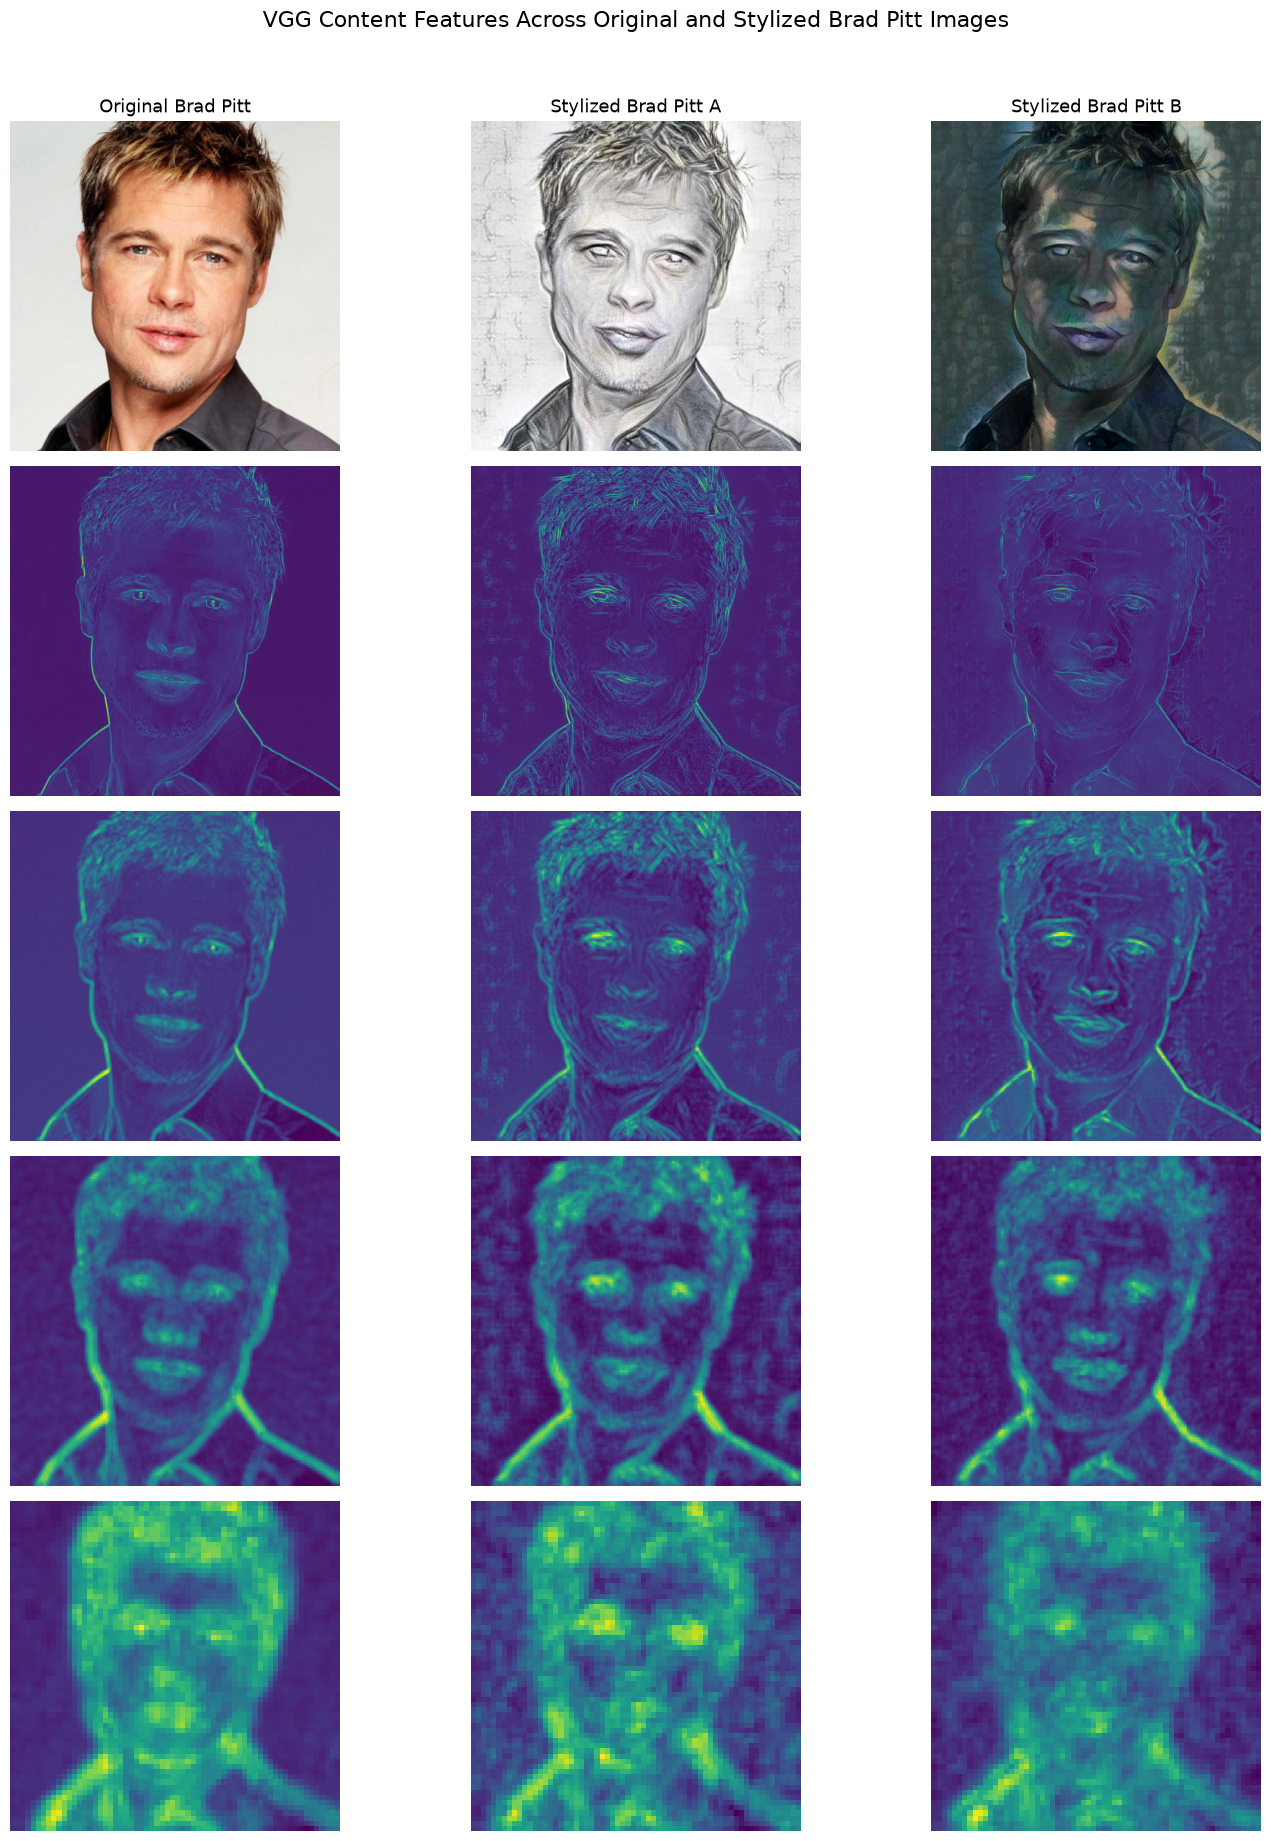

In [12]:

layers_to_show = ["relu1_1", "relu2_1", "relu3_1", "relu4_1"]
row_labels = ["Input Image"] + layers_to_show

num_rows = len(row_labels)
num_cols = len(image_paths)

fig, axes = plt.subplots(
    num_rows,
    num_cols,
    figsize=(5 * num_cols, 3.6 * num_rows),
    squeeze=False
)

for col, (name, path) in enumerate(image_paths.items()):
    image = Image.open(path).convert("RGB")

    # Input image
    axes[0, col].imshow(image)
    axes[0, col].set_title(name, fontsize=13)
    axes[0, col].axis("off")

    # Activation maps for this image
    for row, layer in enumerate(layers_to_show, start=1):
        axes[row, col].imshow(
            activation_map(feature_bank[name][layer]),
            cmap="viridis"
        )
        axes[row, col].axis("off")

# Row labels
for row, label in enumerate(row_labels):
    axes[row, 0].set_ylabel(
        label, fontsize=12, rotation=90, labelpad=18
    )

plt.suptitle(
    "VGG Content Features Across Original and Stylized Brad Pitt Images",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()
